# Analysis and figure notebook (revised for AJSR)
**Listening Intention, Age, and Music Streaming Behaviors: A Cross-Sectional Survey of Active and Background Listening**

Reproduces every number, table and figure in the revised manuscript (Figures 1-7, Supplementary Figures 1-9, Tables 1-2, Supplementary Table 1).

**Changes relative to the earlier notebook (response to reviewers)**
1. *Missing values are preserved.* The one respondent who preferred not to say their age has no age value (**NaN**) and is excluded from age analyses. Unanswered skip/replay items stay NaN and are dropped from the models that use them; they are never placed in the highest ordinal category or the low-skipping group.
2. *Flow counts*: initial responses, exclusions and the valid n of every principal analysis are printed (Table 1).
3. *Workplace analyses use an explicit eligible population* (employed AND listens while working). Observed eligible responses are primary; mean substitution is a labelled sensitivity analysis only.
4. *Post hoc tests*: Dunn with Holm correction (the Methods now say so). Primary tests (H1x2, H2, H3x2) get Holm-adjusted p; exploratory tests get Benjamini-Hochberg q.
5. *Effect sizes with uncertainty*: bootstrap CIs for the principal contrasts, and a **sensitivity** power calculation (minimum detectable f at 80% power), not observed power.
6. *Path checks*: total, direct and bootstrapped indirect effects for both mediation checks (the mood outcome model now contains age and mood).
7. Figure error bars are explicit (95% percentile bootstrap CI) and age axes use band labels.

**Setup.** Set `DATA_PATH` and edit `COLS` and the label maps below so they match your Google-Form export. If the file is missing, a **synthetic** raw file is generated so the code can be tested; synthetic output must never be used in the paper.

In [1]:
import os, json, warnings, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import networkx as nx
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import FTestAnovaPower
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from matplotlib.patches import FancyBboxPatch
warnings.filterwarnings('ignore')
SEED = 42; rng = np.random.default_rng(SEED); NBOOT = 5000
os.makedirs('figures', exist_ok=True); os.makedirs('output', exist_ok=True)
sns.set_theme(style='whitegrid', context='paper')
plt.rcParams.update({'savefig.dpi':300,'savefig.bbox':'tight','font.family':'DejaVu Sans'})
INTENTS = ['Intentional','Background','Mix']
PAL = {'Intentional':'#1f77b4','Background':'#ff7f0e','Mix':'#2ca02c'}
AGE_ORDER = ['Below 18','18-29','30-49','50-69','70+']
NUM = {}                      # numbers destined for the manuscript
def save(fig, name): fig.savefig(f'figures/{name}.png'); fig.savefig(f'figures/{name}.pdf'); plt.show()
def fmt_p(p): return '< .001' if p < .001 else f'{p:.3f}'.lstrip('0')

## 1. Configuration: file and columns

In [2]:
DATA_PATH = 'Untitled_spreadsheet.xlsx'      # the (already numerically coded) survey export, 230 rows

# internal name -> column name in the file
COLS = dict(age='age', gender='gender', in_us='in_us', intent='intent', skips='skips', replays='replays',
            artists='artist_count', genres='genre_count', session='session_length', mood='mood',
            jobsat='job_satisfaction', jobeff='job_effectiveness', time='Timestamp')
# The export holds band midpoints, not the original answer labels:
#   skips/replays 0, 3, 8, 15.5, 25 (25 = open-ended top band) | artists/genres 1, 3, 7.5, 12 (12 = top band)
#   session length (min) 10, 37.5, 90, 180 (180 = '2+ hours') | age 17, 23.5, 39.5, 59.5, 75
# Age: the single respondent who chose 'prefer not to say' has no age value in this file and is treated as missing.

In [3]:
def make_synthetic(n=230, seed=SEED):
    r = np.random.default_rng(seed)
    elig = r.random(n) < .59
    return pd.DataFrame({'Timestamp':['2026/01/10 11:00:00 PM EST']*n, 'age':r.choice([17,23.5,39.5,59.5,75],n,p=[.09,.40,.35,.145,.015]),
      'gender':r.choice(['Male','Female','Other'],n,p=[.51,.38,.11]), 'in_us':r.choice(['Yes','No'],n,p=[.62,.38]),
      'session_length':r.choice([10,37.5,90,180],n,p=[.02,.48,.29,.21]), 'intent':r.choice(['Intentional','Background','Mix','Other'],n,p=[.157,.187,.622,.034]),
      'skips':r.choice([0,3,8,15.5,25],n,p=[.28,.5,.12,.07,.03]), 'replays':r.choice([0,3,8,15.5,25],n,p=[.33,.55,.07,.04,.01]),
      'artist_count':r.choice([1,3,7.5,12],n,p=[.1,.3,.33,.27]), 'genre_count':r.choice([1,3,7.5,12],n,p=[.23,.62,.11,.04]),
      'mood':np.clip(r.normal(8,1.5,n).round(),1,10), 'job_satisfaction':np.where(elig,np.clip(r.normal(3.8,.9,n).round(),1,5),3.875),
      'job_effectiveness':np.where(elig,np.clip(r.normal(3.9,.8,n).round(),1,5),np.nan)})
SYNTHETIC = not os.path.exists(DATA_PATH)
raw = make_synthetic() if SYNTHETIC else pd.read_excel(DATA_PATH)
if SYNTHETIC: print('!! SYNTHETIC data in use - results are placeholders, never report them !!')
print('Rows in file (retained responses):', len(raw))

Rows in file (retained responses): 230


## 2. Exclusions and recoding (missing values preserved) - Table 1 inputs

In [4]:
flow = [('Responses in file (all respondents; none excluded)', len(raw))]
d = raw.copy()
df = pd.DataFrame(index=d.index)
AGE_LAB = {17:'Below 18',23.5:'18-29',39.5:'30-49',59.5:'50-69',75:'70+'}
df['age'] = pd.to_numeric(d[COLS['age']], errors='coerce'); df['age_band'] = pd.Categorical(df.age.map(AGE_LAB), AGE_ORDER, ordered=True)
print('Respondents with missing age (the one who preferred not to say):', int(df.age.isna().sum()))
df['gender'] = d[COLS['gender']]; df['in_us'] = d[COLS['in_us']]
df['intent_raw'] = d[COLS['intent']]; df['intent'] = pd.Categorical(d[COLS['intent']].where(d[COLS['intent']].isin(INTENTS)), INTENTS)   # 'Other' -> NaN for group tests
for k in ['skips','replays','artists','genres','session','mood','jobsat','jobeff']: df[k] = pd.to_numeric(d[COLS[k]], errors='coerce')   # missing stays NaN
# Eligibility: respondents with a job-effectiveness answer. In this file the 94 respondents without one all carry the
# mean-imputed job-satisfaction value 3.875, i.e. the old imputation was applied exactly to them.
df['eligible'] = df['jobeff'].notna()
df['jobsat_imputed_original'] = df['jobsat']                      # as in the original analysis (mean substituted for 94)
df.loc[~df['eligible'], 'jobsat'] = np.nan                         # primary: inapplicable, not imputed
df['jobsat_sub'] = df['jobsat'].fillna(df.loc[df.eligible,'jobsat'].mean())   # sensitivity only: mean substitution for all 230
df['skips_per_hour'] = df['skips'] / (df['session']/60)
ts = pd.to_datetime(d[COLS['time']].str.replace(' EST','', regex=False), format='%Y/%m/%d %I:%M:%S %p', errors='coerce'); NUM['response_window'] = [str(ts.min()), str(ts.max())]
print('Age missing:', int(df.age.isna().sum()), '| Other intent:', int((df.intent_raw=='Other').sum()), '| eligible:', int(df.eligible.sum()), '| responses', NUM['response_window'])
def n_by_group(col, sub=None):
    x = df if sub is None else df[sub]
    return x.dropna(subset=[col,'intent']).groupby('intent', observed=True).size().reindex(INTENTS).to_dict()
flow += [('H1 skips: n by intent', n_by_group('skips')), ('H1 replays: n by intent', n_by_group('replays')),
         ('H2 age & skips: valid n', int(df[['age','skips']].dropna().shape[0])),
         ('H3 job effectiveness (eligible): n by intent', n_by_group('jobeff', df.eligible)),
         ('H3 job satisfaction (eligible): n by intent', n_by_group('jobsat', df.eligible))]
table1 = pd.DataFrame(flow, columns=['Step / analysis','Valid n']); table1.to_csv('output/table1_flow.csv', index=False); NUM['flow'] = flow
table1

Respondents with missing age (the one who preferred not to say): 1
Age missing: 1 | Other intent: 8 | eligible: 136 | responses ['2026-01-10 23:44:20', '2026-02-08 02:41:22']


,Step / analysis,Valid n
0,Responses in file (all respondents; none exclu...,230
1,H1 skips: n by intent,"{'Intentional': 36, 'Background': 43, 'Mix': 142}"
2,H1 replays: n by intent,"{'Intentional': 36, 'Background': 43, 'Mix': 143}"
3,H2 age & skips: valid n,228
4,H3 job effectiveness (eligible): n by intent,"{'Intentional': 22, 'Background': 24, 'Mix': 86}"
5,H3 job satisfaction (eligible): n by intent,"{'Intentional': 22, 'Background': 24, 'Mix': 86}"


## 3. Descriptives (Table 2) and demographics

In [5]:
g = df.dropna(subset=['intent']).groupby('intent', observed=True)
t2 = pd.concat({'n':g.size(), 'session_mean':g.session.mean(),
    'skips_mean':g.skips.mean(),'skips_sd':g.skips.std(),'replays_mean':g.replays.mean(),'replays_sd':g.replays.std(),
    'artists_mean':g.artists.mean(),'artists_sd':g.artists.std(),'genres_mean':g.genres.mean(),'mood_mean':g.mood.mean(),
    'jobsat_mean':g.jobsat.mean(),'jobsat_n':g.jobsat.count(),'jobeff_mean':g.jobeff.mean(),'jobeff_n':g.jobeff.count()},axis=1).T.round(2)
t2.to_csv('output/table2_descriptives.csv'); NUM['table2'] = t2.to_dict()
demo = {c: (df[c].value_counts(normalize=True, dropna=False)*100).round(1).to_dict() for c in ['age_band','gender','in_us']}
NUM['demographics'] = {k:{str(a):b for a,b in v.items()} for k,v in demo.items()}
print(t2); print(demo)

intent        Intentional  Background     Mix
n                   36.00       43.00  143.00
session_mean        76.46       72.80   84.70
skips_mean           2.60        3.83    3.76
skips_sd             3.17        3.92    4.83
replays_mean         2.49        2.05    3.08
replays_sd           2.83        1.98    4.01
artists_mean         5.79        8.19    6.56
artists_sd           4.05        3.74    3.75
genres_mean          2.67        3.45    3.29
mood_mean            8.14        7.71    8.17
jobsat_mean          3.68        3.88    3.92
jobsat_n            22.00       24.00   86.00
jobeff_mean          3.55        3.96    4.19
jobeff_n            22.00       24.00   86.00
{'age_band': {'18-29': 40.4, '30-49': 34.3, '50-69': 14.8, 'Below 18': 8.7, '70+': 1.3, nan: 0.4}, 'gender': {'Male': 50.9, 'Female': 38.3, 'Other': 10.9}, 'in_us': {'Yes': 61.7, 'No': 37.4, nan: 0.4, 'Prefer not to say': 0.4}}


## 4. Helper functions: bootstrap CIs, Dunn-Holm, effect sizes, sensitivity power

In [6]:
def boot_ci(fn, *arrs, n=NBOOT):
    arrs = [np.asarray(a) for a in arrs]; out = []
    for _ in range(n):
        idx = [rng.integers(0, len(a), len(a)) for a in arrs]; out.append(fn(*[a[i] for a,i in zip(arrs,idx)]))
    return np.percentile(out, [2.5, 97.5])
def mean_diff(a, b): return float(np.mean(a) - np.mean(b))
def kw(y, grp):
    gs = [y[grp==k].dropna() for k in INTENTS]; H, p = stats.kruskal(*gs); n = sum(len(x) for x in gs)
    return dict(H=H, p=p, eps2=H*(n+1)/(n**2-1), n=n)
def dunn_holm(y, grp):
    x = pd.DataFrame({'y':y,'g':grp}).dropna(); x['r'] = stats.rankdata(x.y); N = len(x)
    _, cnt = np.unique(x.y, return_counts=True); tie = 1 - (cnt**3 - cnt).sum()/(N**3 - N)
    res = []
    for i, a in enumerate(INTENTS):
        for b in INTENTS[i+1:]:
            ra, rb = x.r[x.g==a], x.r[x.g==b]; se = np.sqrt(N*(N+1)/12*tie*(1/len(ra)+1/len(rb)))
            z = (ra.mean()-rb.mean())/se; res.append((a, b, z, 2*stats.norm.sf(abs(z))))
    out = pd.DataFrame(res, columns=['A','B','z','p']); out['p_holm'] = multipletests(out.p, method='holm')[1]; return out
def min_detectable_f(ns, alpha=.05, power=.80):
    return FTestAnovaPower().solve_power(effect_size=None, nobs=sum(ns), alpha=alpha, power=power, k_groups=len(ns))
def spearman_ci(x, y):
    m = pd.concat([x,y],axis=1).dropna(); r, p = stats.spearmanr(m.iloc[:,0], m.iloc[:,1])
    pair = m.values  # resample rows jointly so pairs stay intact
    lo, hi = boot_ci(lambda P: stats.spearmanr(P[:,0], P[:,1])[0], pair, n=2000)
    return dict(rho=r, p=p, ci=[lo,hi], n=len(m))

## 5. Primary tests: H1, H2, H3 (Holm-adjusted across the five primary tests)

In [7]:
prim = {}
G = df.dropna(subset=['intent'])
for v in ['skips','replays']:
    prim[f'H1_{v}'] = kw(G[v], G['intent'])
# principal contrast: Intentional - Background (mean difference, bootstrap CI, Hedges g)
def contrast(v, a='Intentional', b='Background', data=G):
    xa, xb = data.loc[data.intent==a, v].dropna().values, data.loc[data.intent==b, v].dropna().values
    d_ = mean_diff(xa, xb); lo, hi = boot_ci(mean_diff, xa, xb)
    sp = np.sqrt(((len(xa)-1)*xa.var(ddof=1)+(len(xb)-1)*xb.var(ddof=1))/(len(xa)+len(xb)-2))
    return dict(diff=d_, ci=[lo,hi], g=d_/sp, na=len(xa), nb=len(xb))
for v in ['skips','replays']: prim[f'H1_{v}']['contrast_Int_minus_Bg'] = contrast(v)
ns = [G.dropna(subset=['skips']).query('intent==@k').shape[0] for k in INTENTS]
f80 = min_detectable_f(ns); prim['H1_sensitivity'] = dict(ns=ns, f80=f80, eps2_80=f80**2/(1+f80**2))
# H2: Spearman age band ~ skips (prefer-not-to-say already NaN)
prim['H2'] = spearman_ci(df['age'], df['skips']); prim['H2_normalised'] = spearman_ci(df['age'], df['skips_per_hour'])
prim['H2_by_intent'] = {k: spearman_ci(df.loc[df.intent==k,'age'], df.loc[df.intent==k,'skips']) for k in INTENTS}
# H3: eligible respondents only, Background vs Intentional
E = df[df.eligible & df.intent.isin(['Background','Intentional'])]
for v in ['jobeff','jobsat']:
    a, b = E.loc[E.intent=='Background', v].dropna(), E.loc[E.intent=='Intentional', v].dropna()
    lev = stats.levene(a, b).pvalue; t, p = stats.ttest_ind(a, b, equal_var=lev > .05)
    lo, hi = boot_ci(mean_diff, a.values, b.values)
    prim[f'H3_{v}'] = dict(t=t, p=p, levene_p=lev, diff_Bg_minus_Int=mean_diff(a,b), ci=[lo,hi], n_bg=len(a), n_int=len(b),
                          mannwhitney_p=stats.mannwhitneyu(a,b).pvalue)
prim['H3_jobeff_KW3'] = kw(df[df.eligible]['jobeff'], df[df.eligible]['intent'])   # exploratory 3-group check
fam = ['H1_skips','H1_replays','H2','H3_jobeff','H3_jobsat']
praw = [prim[k]['p'] for k in fam]; padj = multipletests(praw, method='holm')[1]
for k, pa in zip(fam, padj): prim[k]['p_holm'] = pa
NUM['primary'] = prim
pd.DataFrame({'test':fam,'p':praw,'p_holm':padj}).round(4)

,test,p,p_holm
0,H1_skips,0.2035,0.8138
1,H1_replays,0.4083,0.8166
2,H2,0.0033,0.0167
3,H3_jobeff,0.2067,0.8138
4,H3_jobsat,0.4928,0.8166


## 6. Exploratory analyses (Benjamini-Hochberg across the exploratory family) - Supplementary Table 1

In [8]:
expl = []
def add(name, p): expl.append((name, p))
kwa = kw(G['artists'], G['intent']); add('KW artist count by intent', kwa['p'])
dun = dunn_holm(G['artists'], G['intent']); NUM['dunn_artists'] = dun.round(4).to_dict('records'); print(dun.round(4))
NUM['artist_contrast_Bg_minus_Int'] = contrast('artists','Background','Intentional')
for a,b in [('skips','artists'),('skips','genres'),('replays','artists'),('replays','genres'),('artists','genres'),
            ('session','skips'),('session','replays'),('session','genres')]:
    r = spearman_ci(df[a], df[b]); NUM[f'rho_{a}_{b}'] = r; add(f'Spearman {a}-{b}', r['p'])
r = spearman_ci(E['age'] if False else df.loc[df.eligible,'age'], df.loc[df.eligible,'jobeff']); NUM['rho_age_jobeff'] = r; add('Spearman age-jobeff (eligible)', r['p'])
# interactions (rows with all variables observed only)
d1 = df.dropna(subset=['skips','age','mood']).copy(); d1['age_c']=d1.age-d1.age.mean(); d1['mood_c']=d1.mood-d1.mood.mean()
m1 = smf.ols('skips ~ age_c*mood_c', d1).fit(); NUM['int_age_mood'] = dict(b=m1.params['age_c:mood_c'], p=m1.pvalues['age_c:mood_c'], n=int(m1.nobs)); add('age x mood', m1.pvalues['age_c:mood_c'])
d2 = G.dropna(subset=['skips']).copy(); d2 = d2[d2.gender.isin(['Male','Female'])]
a2 = sm.stats.anova_lm(smf.ols('skips ~ C(gender)*C(intent)', d2).fit(), typ=2); NUM['anova_gender_intent'] = a2.round(4).to_dict(); add('gender x intent', a2.loc['C(gender):C(intent)','PR(>F)'])
d3 = G.dropna(subset=['skips']); d3 = d3[d3.in_us.isin(['Yes','No'])]
a3 = sm.stats.anova_lm(smf.ols('skips ~ C(in_us)*C(intent)', d3).fit(), typ=2); NUM['anova_us_intent'] = a3.round(4).to_dict(); add('US x intent', a3.loc['C(in_us):C(intent)','PR(>F)'])
mf = df.loc[df.gender=='Male','skips'].dropna(); ff = df.loc[df.gender=='Female','skips'].dropna(); add('gender t-test skips', stats.ttest_ind(mf, ff, equal_var=False).pvalue)
ST1 = pd.DataFrame(expl, columns=['test','p']); ST1['q_BH'] = multipletests(ST1.p, method='fdr_bh')[1]
ST1.round(4).to_csv('output/supp_table1_exploratory_BH.csv', index=False); NUM['supp_table1'] = ST1.round(4).to_dict('records'); ST1.round(4)

             A           B       z       p  p_holm
0  Intentional  Background -2.8169  0.0048  0.0145
1  Intentional         Mix -1.1650  0.2440  0.2440
2   Background         Mix  2.4099  0.0160  0.0319


,test,p,q_BH
0,KW artist count by intent,0.0124,0.0347
1,Spearman skips-artists,0.0000,0.0000
2,Spearman skips-genres,0.0000,0.0000
3,Spearman replays-artists,0.1981,0.2985
4,Spearman replays-genres,0.0029,0.0102
5,Spearman artists-genres,0.0000,0.0000
6,Spearman session-skips,0.8824,0.9025
7,Spearman session-replays,0.1638,0.2909
8,Spearman session-genres,0.5089,0.5937
9,Spearman age-jobeff (eligible),0.0242,0.0566


## 7. Multivariable models (missing outcomes dropped, never recoded)

In [9]:
M = df.dropna(subset=['skips','age','mood','intent']).copy()
M['intent_code'] = M.intent.map({'Intentional':0,'Mix':1,'Background':2}).astype(float)   # state this coding in the Methods
# ordinal logistic on skip category (bands -> ordered categories; NaN rows excluded)
cats = sorted(M.skips.unique()); M['skip_cat'] = pd.Categorical(M.skips, categories=cats, ordered=True)
om = OrderedModel(M['skip_cat'], M[['intent_code','age','mood']], distr='logit').fit(method='bfgs', disp=0)
NUM['ordinal'] = dict(params=om.params.round(4).to_dict(), se=om.bse.round(4).to_dict(), p=om.pvalues.round(4).to_dict(), n=len(M))
# binary: high skipper = above the median of OBSERVED skips; missing skips stay missing
med = df.skips.median(); M['high'] = (M.skips > med).astype(int)
lg = smf.logit('high ~ intent_code + age + mood', M).fit(disp=0)
orr = np.exp(lg.params); oci = np.exp(lg.conf_int())
NUM['logit'] = dict(median=med, n=len(M), OR=orr.round(3).to_dict(), CI=oci.round(3).values.tolist(), p=lg.pvalues.round(4).to_dict(), llr_p=lg.llr_pvalue, pseudoR2=lg.prsquared)
print(NUM['ordinal']); print(NUM['logit'])

{'params': {'intent_code': 0.2785, 'age': -0.0274, 'mood': -0.1649, '0.0/3.0': -2.9797, '3.0/8.0': 0.9611, '8.0/15.5': 0.2756, '15.5/25.0': 0.1374}, 'se': {'intent_code': 0.2213, 'age': 0.0095, 'mood': 0.0883, '0.0/3.0': 0.8669, '3.0/8.0': 0.0804, '8.0/15.5': 0.1953, '15.5/25.0': 0.3645}, 'p': {'intent_code': 0.2082, 'age': 0.004, 'mood': 0.0619, '0.0/3.0': 0.0006, '3.0/8.0': 0.0, '8.0/15.5': 0.1582, '15.5/25.0': 0.7063}, 'n': 219}
{'median': np.float64(3.0), 'n': 219, 'OR': {'Intercept': 3.072, 'intent_code': 1.242, 'age': 0.966, 'mood': 0.797}, 'CI': [[0.349, 27.063], [0.674, 2.287], [0.937, 0.997], [0.639, 0.992]], 'p': {'Intercept': 0.3121, 'intent_code': 0.4875, 'age': 0.0293, 'mood': 0.0425}, 'llr_p': np.float64(0.02019525236097528), 'pseudoR2': np.float64(0.048570581239716804)}


## 8. Preliminary path checks: total, direct and bootstrapped indirect effects

In [10]:
def path_check(data, x, m, y, n=NBOOT):
    dd = data[[x,m,y]].dropna(); X = sm.add_constant(dd[[x]]); a = sm.OLS(dd[m], X).fit()
    tot = sm.OLS(dd[y], X).fit(); full = sm.OLS(dd[y], sm.add_constant(dd[[x,m]])).fit()
    def ind(d_):
        a_ = np.polyfit(d_[x], d_[m], 1)[0]; b_ = sm.OLS(d_[y], sm.add_constant(d_[[x,m]])).fit().params[m]; return a_*b_
    bs = [ind(dd.iloc[rng.integers(0, len(dd), len(dd))]) for _ in range(n)]
    return dict(n=len(dd), a=a.params[x], a_p=a.pvalues[x], total=tot.params[x], total_p=tot.pvalues[x],
                direct=full.params[x], direct_p=full.pvalues[x], b=full.params[m], b_p=full.pvalues[m],
                indirect=ind(dd), indirect_ci=np.percentile(bs,[2.5,97.5]).tolist())
NUM['path_mood_jobeff'] = path_check(df[df.eligible], 'age', 'mood', 'jobeff')      # outcome model contains age AND mood
NUM['path_artists_skips'] = path_check(df, 'age', 'artists', 'skips')
print(json.dumps({k:NUM[k] for k in ['path_mood_jobeff','path_artists_skips']}, indent=1, default=float))

{
 "path_mood_jobeff": {
  "n": 136,
  "a": -0.0018825131404946044,
  "a_p": 0.8287635270346723,
  "total": 0.005283977599105033,
  "total_p": 0.360820068318142,
  "direct": 0.0053916396361431175,
  "direct_p": 0.3512532234693334,
  "b": 0.05719058992050302,
  "b_p": 0.3201149620190246,
  "indirect": -0.00010766203703798151,
  "indirect_ci": [
   -0.0018590123066819229,
   0.0013591886716373426
  ]
 },
 "path_artists_skips": {
  "n": 228,
  "a": -0.019784384627375206,
  "a_p": 0.2777656632560696,
  "total": -0.059369934571799975,
  "total_p": 0.004419368699566217,
  "direct": -0.05270582132255076,
  "direct_p": 0.008371634159977851,
  "b": 0.33683702448992353,
  "b_p": 5.418919771136549e-06,
  "indirect": -0.006664113249249257,
  "indirect_ci": [
   -0.01992887067799655,
   0.005069673336754057
  ]
 }
}


## 9. Sensitivity analyses: mean substitution for job satisfaction (never the primary result)

In [11]:
Eb = df[df.intent.isin(['Background','Intentional'])]            # ALL respondents, as in the original (imputed) analysis
a, b = Eb.loc[Eb.intent=='Background','jobsat_sub'], Eb.loc[Eb.intent=='Intentional','jobsat_sub']
t, p = stats.ttest_ind(a, b, equal_var=False)
cc = df[df.eligible].dropna(subset=['mood','jobsat'])
NUM['sens_meansub'] = dict(t=t, p=p, n=len(a)+len(b), r_observed=stats.pearsonr(cc.mood, cc.jobsat)[0], n_observed=len(cc),
                           r_substituted=stats.pearsonr(*df[['mood','jobsat_sub']].dropna().T.values)[0], n_substituted=int(df[['mood','jobsat_sub']].dropna().shape[0]))
NUM['sens_meansub']

{'t': np.float64(0.7053619341683455),
 'p': np.float64(0.48327586040284093),
 'n': 79,
 'r_observed': np.float64(0.4354512485003492),
 'n_observed': 136,
 'r_substituted': np.float64(0.29498322275305155),
 'n_substituted': 227}

## 10. Main-text figures 1-7

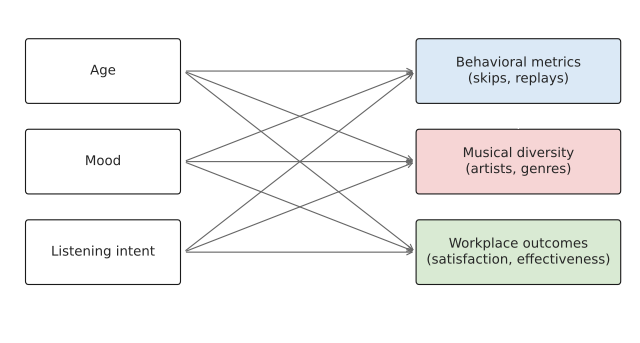

In [12]:
# Figure 1: conceptual framework
fig, ax = plt.subplots(figsize=(8,4.2)); ax.axis('off'); ax.set_xlim(0,10); ax.set_ylim(0,5)
def box(x,y,w,h,t,c): ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.05',fc=c,ec='k')); ax.text(x+w/2,y+h/2,t,ha='center',va='center')
for y,t in zip([3.6,2.2,0.8],['Age','Mood','Listening intent']): box(.3,y,2.4,.9,t,'white')
for y,t,c in zip([3.6,2.2,0.8],['Behavioral metrics\n(skips, replays)','Musical diversity\n(artists, genres)','Workplace outcomes\n(satisfaction, effectiveness)'],['#dbe9f6','#f6d5d5','#d9ead3']): box(6.6,y,3.2,.9,t,c)
for y1 in (4.05,2.65,1.25):
    for y2 in (4.05,2.65,1.25): ax.annotate('',xy=(6.55,y2),xytext=(2.8,y1),arrowprops=dict(arrowstyle='->',color='#666',lw=.8))
ax.annotate('',xy=(8.2,3.55),xytext=(8.2,3.1),arrowprops=dict(arrowstyle='<->',ls='--'))
save(fig,'fig1_framework')

In [13]:
# Figure 3: violins (cut=0 so density never extends below the observed minimum)
fig, axs = plt.subplots(1,2,figsize=(10,4.2))
for ax,(v,lab,L) in zip(axs,[('skips','Skips (estimated count)','A'),('replays','Replays (estimated count)','B')]):
    sns.violinplot(data=G,x='intent',y=v,order=INTENTS,palette=PAL,inner='box',cut=0,ax=ax); ax.set_xlabel('Listening intent'); ax.set_ylabel(lab)
    ax.set_title(L, loc='left', fontweight='bold')
plt.tight_layout(); save(fig,'fig3_violins')

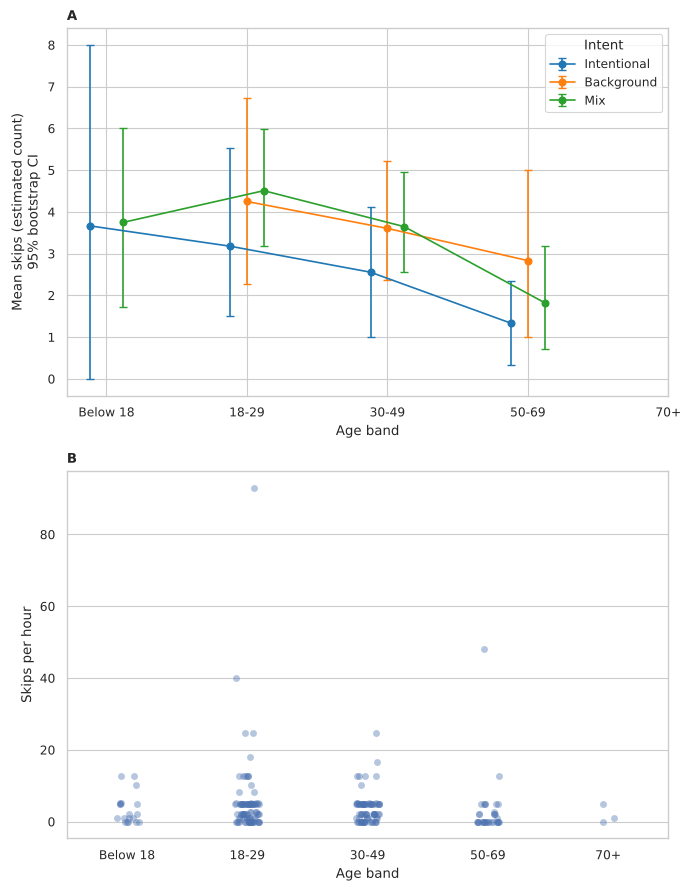

In [15]:
# Figure 4: (A) mean skips by age band x intent (95% bootstrap CI); (B) skips/hour by age band
fig, axs = plt.subplots(2,1,figsize=(7,9))
ax = axs[0]
for k,off in zip(INTENTS,[-.12,0,.12]):
    xs, ms, los, his = [], [], [], []
    for i,ab in enumerate(AGE_ORDER):
        v = df[(df.intent==k)&(df.age_band==ab)].skips.dropna().values
        if len(v) < 3: continue
        lo,hi = boot_ci(np.mean, v, n=1000); xs.append(i+off); ms.append(v.mean()); los.append(v.mean()-lo); his.append(hi-v.mean())
    ax.errorbar(xs, ms, yerr=[los,his], marker='o', capsize=3, label=k, color=PAL[k])
ax.set_xticks(range(5)); ax.set_xticklabels(AGE_ORDER); ax.set_xlabel('Age band'); ax.set_ylabel('Mean skips (estimated count)\n95% bootstrap CI'); ax.legend(title='Intent'); ax.set_title('A',loc='left',fontweight='bold')
ax = axs[1]; dd = df.dropna(subset=['age_band','skips_per_hour'])
sns.stripplot(data=dd,x='age_band',y='skips_per_hour',order=AGE_ORDER,alpha=.4,ax=ax,color='#4c72b0'); ax.set_xlabel('Age band'); ax.set_ylabel('Skips per hour'); ax.set_title('B',loc='left',fontweight='bold')
plt.tight_layout(); save(fig,'fig4_age_skips')

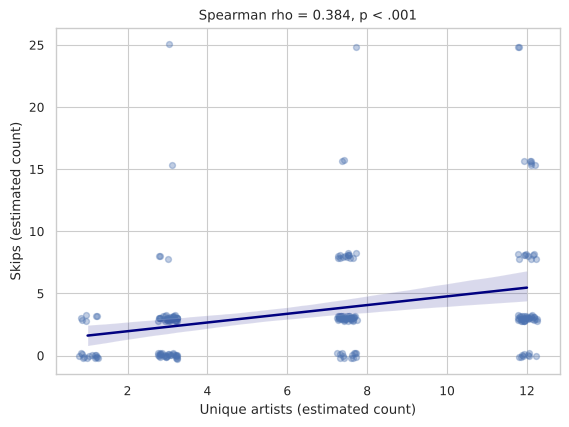

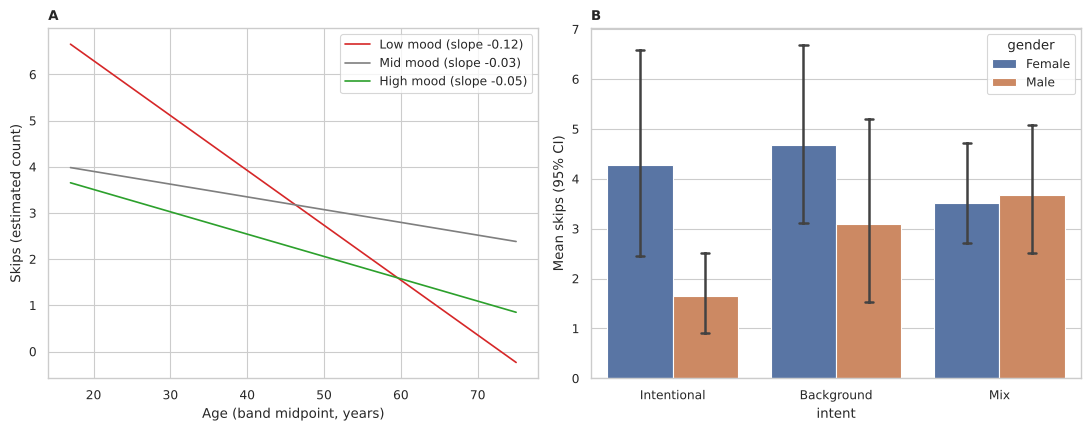

In [16]:
# Figure 5: skips vs artists
fig, ax = plt.subplots(figsize=(6.5,4.5)); dd = df.dropna(subset=['skips','artists'])
sns.regplot(data=dd,x='artists',y='skips',x_jitter=.25,y_jitter=.25,ci=95,scatter_kws=dict(alpha=.35,s=18),line_kws=dict(color='navy'),ax=ax)
r_ = NUM['rho_skips_artists']; ax.set_title(f"Spearman rho = {r_['rho']:.3f}, p {fmt_p(r_['p'])}"); ax.set_xlabel('Unique artists (estimated count)'); ax.set_ylabel('Skips (estimated count)')
save(fig,'fig5_skips_artists')
# Figure 6: (A) age x mood by tercile; (B) gender x intent
fig, axs = plt.subplots(1,2,figsize=(11,4.4)); d1['mood_t'] = pd.qcut(d1.mood.rank(method='first'),3,labels=['Low mood','Mid mood','High mood'])
for lvl,col in zip(['Low mood','Mid mood','High mood'],['#d62728','#7f7f7f','#2ca02c']):
    s = d1[d1.mood_t==lvl]; l = stats.linregress(s.age,s.skips); xs = np.linspace(d1.age.min(),d1.age.max(),20)
    axs[0].plot(xs,l.intercept+l.slope*xs,color=col,label=f'{lvl} (slope {l.slope:.2f})')
axs[0].set_xlabel('Age (band midpoint, years)'); axs[0].set_ylabel('Skips (estimated count)'); axs[0].legend(); axs[0].set_title('A',loc='left',fontweight='bold')
sns.barplot(data=d2,x='intent',y='skips',hue='gender',order=INTENTS,errorbar=('ci',95),capsize=.1,ax=axs[1]); axs[1].set_ylabel('Mean skips (95% CI)'); axs[1].set_title('B',loc='left',fontweight='bold')
plt.tight_layout(); save(fig,'fig6_moderation')

[['Age', 'Artists', 'Genres', 'Replays', 'Session', 'Skips'], ['Job eff.', 'Job sat.', 'Mood']]


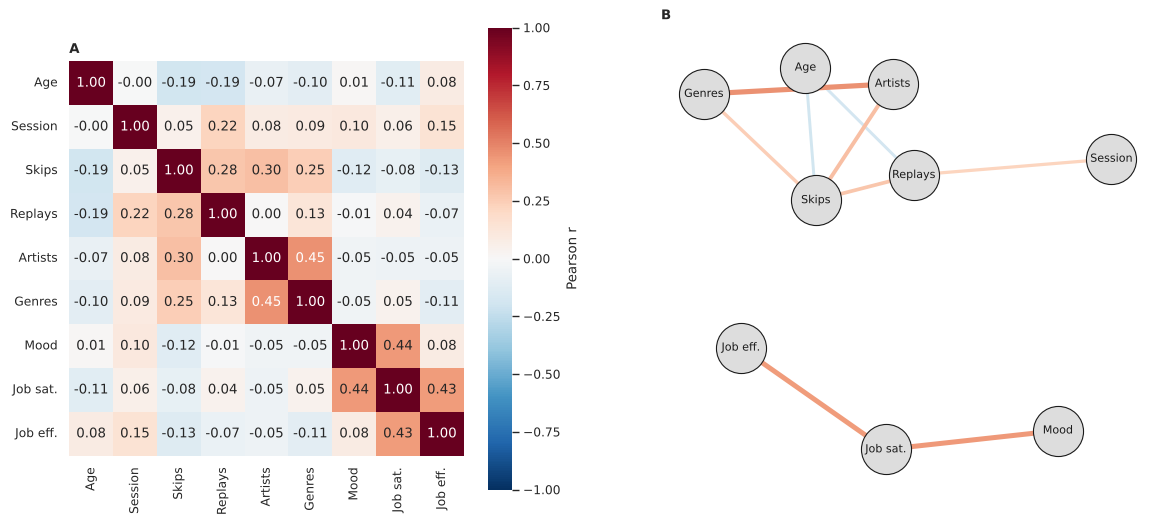

In [17]:
# Figure 7: (A) Pearson matrix, (B) network |r| >= .15 (eligible-observed workplace variables)
vv = ['age','session','skips','replays','artists','genres','mood','jobsat','jobeff']; lab = ['Age','Session','Skips','Replays','Artists','Genres','Mood','Job sat.','Job eff.']
cm = df[vv].corr(); cm.index = cm.columns = lab
fig, axs = plt.subplots(1,2,figsize=(14,6))
sns.heatmap(cm,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-1,vmax=1,square=True,cbar_kws=dict(label='Pearson r'),ax=axs[0]); axs[0].set_title('A',loc='left',fontweight='bold')
Gn = nx.Graph(); Gn.add_nodes_from(lab)
for i,a_ in enumerate(lab):
    for b_ in lab[i+1:]:
        if abs(cm.loc[a_,b_])>=.15: Gn.add_edge(a_,b_,w=cm.loc[a_,b_])
pos = nx.spring_layout(Gn, seed=SEED, k=1.2); w = [Gn[u][v]['w'] for u,v in Gn.edges]
nx.draw_networkx_nodes(Gn,pos,node_color='#dddddd',edgecolors='k',node_size=1300,ax=axs[1]); nx.draw_networkx_labels(Gn,pos,font_size=8,ax=axs[1])
nx.draw_networkx_edges(Gn,pos,width=[1+6*abs(x) for x in w],edge_color=w,edge_cmap=plt.cm.RdBu_r,edge_vmin=-1,edge_vmax=1,ax=axs[1]); axs[1].axis('off'); axs[1].set_title('B',loc='left',fontweight='bold')
NUM['network_components'] = [sorted(c) for c in nx.connected_components(Gn)]; print(NUM['network_components'])
save(fig,'fig7_correlations')

## 11. Supplementary figures 1-9 (numbered in order of first citation in the manuscript)

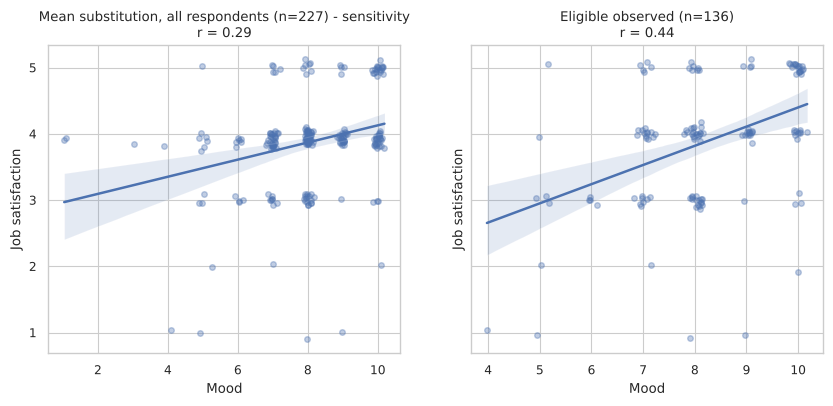

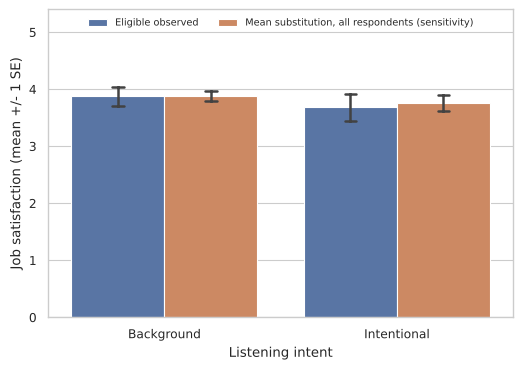

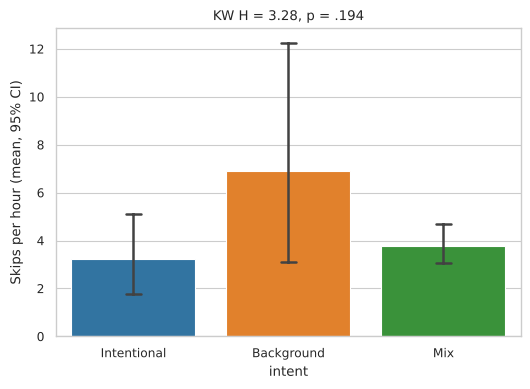

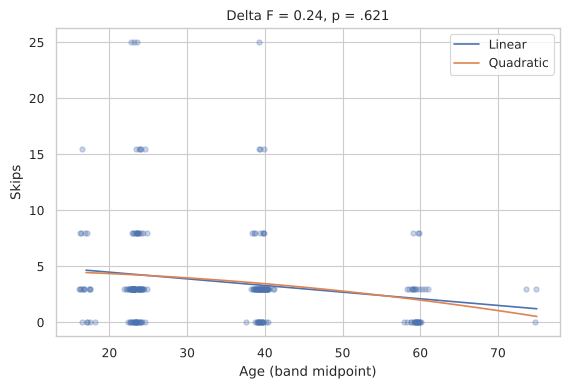

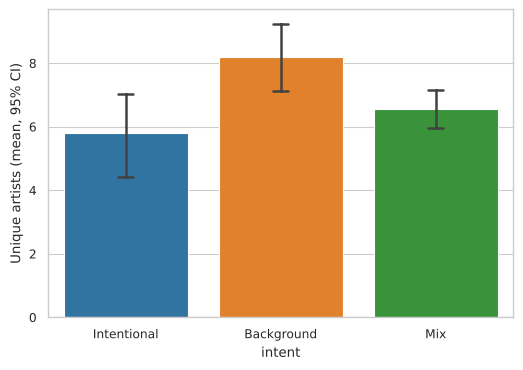

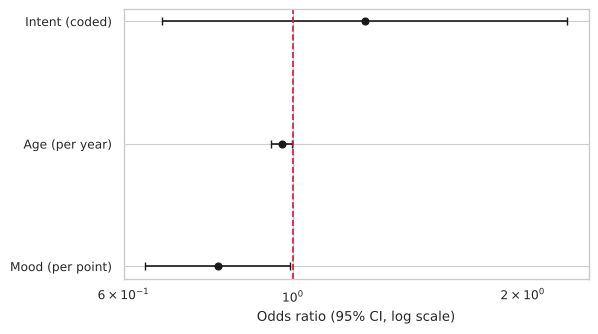

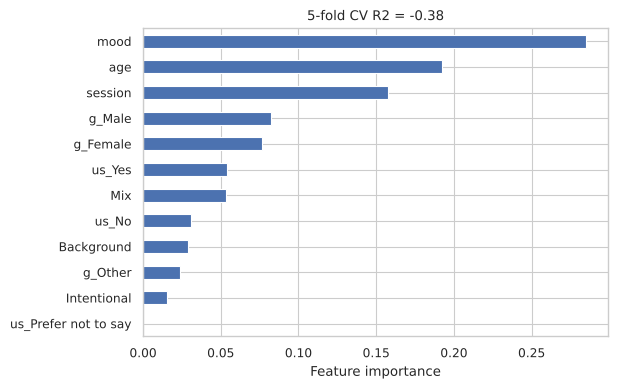

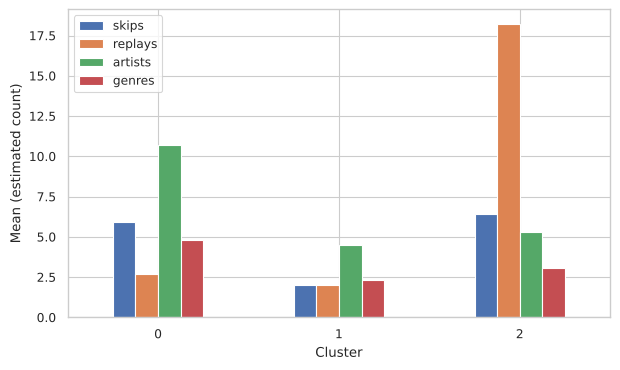

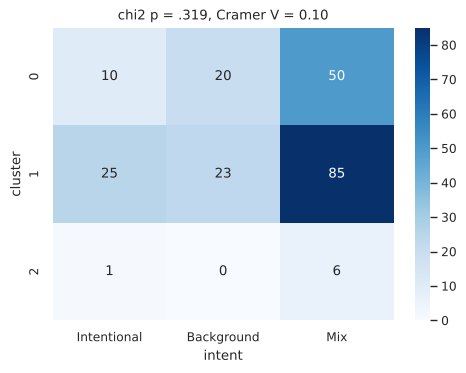

In [18]:
# S1 mood-job satisfaction: mean substitution (left) vs eligible observed (right)
fig, axs = plt.subplots(1,2,figsize=(10,4),sharey=True); El = df
for ax,(y,ttl) in zip(axs,[('jobsat_sub',f'Mean substitution, all respondents (n={El[['mood','jobsat_sub']].dropna().shape[0]}) - sensitivity'),('jobsat',f'Eligible observed (n={El[['mood','jobsat']].dropna().shape[0]})')]):
    s = El.dropna(subset=['mood',y]); sns.regplot(x=s.mood+rng.normal(0,.08,len(s)),y=s[y]+rng.normal(0,.05,len(s)),ax=ax,scatter_kws=dict(alpha=.35,s=16)); ax.set_title(f"{ttl}\nr = {stats.pearsonr(s.mood,s[y])[0]:.2f}"); ax.set_xlabel('Mood'); ax.set_ylabel('Job satisfaction')
save(fig,'supp_fig1_mood_jobsat')
# S2 job satisfaction by intent: observed vs substituted
s2 = pd.concat([Eb.assign(v=Eb.jobsat,kind='Eligible observed'),Eb.assign(v=Eb.jobsat_sub,kind='Mean substitution, all respondents (sensitivity)')]).dropna(subset=['v'])
fig, ax = plt.subplots(figsize=(6,4)); sns.barplot(data=s2,x='intent',y='v',hue='kind',order=['Background','Intentional'],errorbar='se',capsize=.1,ax=ax); ax.set_ylabel('Job satisfaction (mean +/- 1 SE)'); ax.set_xlabel('Listening intent'); ax.set_ylim(0,5.4); ax.legend(title=None,loc='upper center',ncol=2,fontsize=7,frameon=False); save(fig,'supp_fig2_jobsat_by_intent')
# S3 skips per hour by intent
fig, ax = plt.subplots(figsize=(6,4)); sns.barplot(data=G,x='intent',y='skips_per_hour',order=INTENTS,palette=PAL,errorbar=('ci',95),capsize=.1,ax=ax); ax.set_ylabel('Skips per hour (mean, 95% CI)')
NUM['skips_per_hour_KW'] = kw(G['skips_per_hour'], G['intent']); ax.set_title(f"KW H = {NUM['skips_per_hour_KW']['H']:.2f}, p = {fmt_p(NUM['skips_per_hour_KW']['p'])}"); save(fig,'supp_fig3_skip_rate')
# S4 quadratic age
q_ = df.dropna(subset=['age','skips']); m_lin = smf.ols('skips ~ age', q_).fit(); m_q = smf.ols('skips ~ age + I(age**2)', q_).fit(); cmp_ = sm.stats.anova_lm(m_lin, m_q)
NUM['quadratic'] = dict(dF=cmp_['F'].iloc[1], p=cmp_['Pr(>F)'].iloc[1])
xs = np.linspace(q_.age.min(),q_.age.max(),100); fig, ax = plt.subplots(figsize=(6.5,4)); ax.scatter(q_.age+rng.normal(0,.6,len(q_)),q_.skips,alpha=.3,s=14)
ax.plot(xs,m_lin.predict(pd.DataFrame({'age':xs})),label='Linear'); ax.plot(xs,m_q.predict(pd.DataFrame({'age':xs})),label='Quadratic'); ax.legend(); ax.set_xlabel('Age (band midpoint)'); ax.set_ylabel('Skips'); ax.set_title(f"Delta F = {NUM['quadratic']['dF']:.2f}, p = {fmt_p(NUM['quadratic']['p'])}"); save(fig,'supp_fig4_quadratic_age')
# S5 artist count by intent
fig, ax = plt.subplots(figsize=(6,4)); sns.barplot(data=G,x='intent',y='artists',order=INTENTS,palette=PAL,errorbar=('ci',95),capsize=.1,ax=ax); ax.set_ylabel('Unique artists (mean, 95% CI)'); save(fig,'supp_fig5_artists_by_intent')
# S6 odds ratios
t6 = pd.DataFrame({'OR':orr,'lo':oci[0],'hi':oci[1]}).drop('Intercept'); fig, ax = plt.subplots(figsize=(6,3.5))
ax.errorbar(t6.OR,range(len(t6)),xerr=[t6.OR-t6.lo,t6.hi-t6.OR],fmt='o',color='k',capsize=3); ax.axvline(1,ls='--',color='crimson'); ax.set_yticks(range(len(t6))); ax.set_yticklabels(['Intent (coded)','Age (per year)','Mood (per point)']); ax.set_xscale('log'); ax.set_xlabel('Odds ratio (95% CI, log scale)'); ax.invert_yaxis(); save(fig,'supp_fig6_odds_ratios')
# S7 random forest
Xrf = pd.concat([df[['age','mood','session']], pd.get_dummies(df.intent).astype(float), pd.get_dummies(df.gender,prefix='g').astype(float), pd.get_dummies(df.in_us,prefix='us').astype(float)],axis=1)
rf_d = pd.concat([Xrf, df.skips],axis=1).dropna(); rf = RandomForestRegressor(300,min_samples_leaf=3,random_state=SEED)
cv = cross_val_score(rf, rf_d.drop(columns='skips'), rf_d.skips, cv=KFold(5,shuffle=True,random_state=SEED), scoring='r2'); rf.fit(rf_d.drop(columns='skips'), rf_d.skips)
NUM['rf_cv_r2'] = float(cv.mean()); NUM['rf_importance'] = dict(sorted(zip(rf_d.drop(columns='skips').columns, rf.feature_importances_.round(3).tolist()), key=lambda t:-t[1])); NUM['rf_cv_r2_folds'] = cv.round(3).tolist(); fig, ax = plt.subplots(figsize=(6,4)); pd.Series(rf.feature_importances_,rf_d.drop(columns='skips').columns).sort_values().plot.barh(ax=ax,color='#4c72b0'); ax.set_xlabel('Feature importance'); ax.set_title(f'5-fold CV R2 = {cv.mean():.2f}'); save(fig,'supp_fig7_rf_importance')
# S8/S9 clusters
cf = ['skips','replays','artists','genres']; K = df.dropna(subset=cf+['intent']).copy(); K['cluster'] = KMeans(3,n_init=20,random_state=SEED).fit_predict(StandardScaler().fit_transform(K[cf]))
prof = K.groupby('cluster')[cf].mean(); fig, ax = plt.subplots(figsize=(7,4)); prof.plot.bar(ax=ax); ax.set_xlabel('Cluster'); ax.set_ylabel('Mean (estimated count)'); plt.xticks(rotation=0); save(fig,'supp_fig8_cluster_profiles')
ct = pd.crosstab(K.cluster,K.intent); chi2,pc,_,_ = stats.chi2_contingency(ct); V = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
NUM['cluster_chi2'] = dict(chi2=chi2,p=pc,V=V,table=ct.to_dict()); fig, ax = plt.subplots(figsize=(5.5,3.8)); sns.heatmap(ct,annot=True,fmt='d',cmap='Blues',ax=ax); ax.set_title(f'chi2 p = {fmt_p(pc)}, Cramer V = {V:.2f}'); save(fig,'supp_fig9_cluster_by_intent')

## 12. Export every manuscript number

In [19]:
def clean(o):
    if isinstance(o,(np.floating,)): return float(o)
    if isinstance(o,(np.integer,)): return int(o)
    if isinstance(o,np.ndarray): return o.tolist()
    if isinstance(o,dict): return {str(k):clean(v) for k,v in o.items()}
    if isinstance(o,(list,tuple)): return [clean(v) for v in o]
    return o
json.dump(clean(NUM), open('output/manuscript_numbers.json','w'), indent=1)
print('Saved output/manuscript_numbers.json; figures:', sorted(os.listdir('figures'))[:6], '...')
if SYNTHETIC: print('REMINDER: synthetic data - do not use these results.')

Saved output/manuscript_numbers.json; figures: ['fig1_framework.pdf', 'fig1_framework.png', 'fig2_workflow_demographics.pdf', 'fig2_workflow_demographics.png', 'fig3_violins.pdf', 'fig3_violins.png'] ...
